# 📈 Phân Tích & So Sánh Tín Hiệu Latent Z Trước và Sau Khi Smooth (Vòng Bi B12)
## Khắc Phục Hiện Tượng 'Làm Cong Nhầm' Bằng Cơ Chế Post-Onset EWMA (Khởi Động Sau Điểm Cắt Onset)

Notebook này trực quan hóa và đánh giá định lượng chi tiết vector chỉ số sức khỏe $Z$ của **Vòng bi B12** (767 chu kỳ đo đạc) trước và sau khi áp dụng cơ chế làm mượt cải tiến: **EWMA chỉ bắt đầu smooth từ sau đoạn cắt Onset**.

--- 

### 🔍 HIỆN TƯỢNG 'LÀM CONG NHẦM' ĐÃ ĐƯỢC GIẢI QUYẾT NHƯ THẾ NÀO?
1. **Vấn đề của bộ lọc EWMA cũ (Full EWMA từ Cycle 1)**:
   - Cú sốc rơi tự do của B12 bắt đầu từ chu kỳ 67 và chạm đáy ở chu kỳ ~100 ($Z$ rơi từ $+1.5$ xuống $-4.7$).
   - Do EWMA có độ trễ quán tính (Lag), nó bị kéo lê phía sau. Khi tín hiệu thực tế tại chu kỳ 100–140 đã chạm đáy và **bắt đầu đi ngang phẳng**, đường EWMA cũ **vẫn tiếp tục cắm dốc xuống** để 'đuổi kịp' cú sốc trước đó.
   - Nó đã **uốn cong nhầm** một đoạn mòn bằng phẳng thành một sườn dốc nhân tạo, đánh lừa mô hình Wiener Process rằng tốc độ mòn đang rất cao!

2. **Giải pháp Post-Onset EWMA (Khởi động sau điểm cắt Onset)**:
   - **Giai đoạn trước Onset**: Sử dụng **Rolling Median (Window 11)** thuần túy để khử gai nhiễu mà không dùng EWMA. Nhờ đó, tín hiệu bắt chuẩn xác thời điểm chạm đáy cú sốc tại **chu kỳ 100** ($H_{\text{onset}} = 6.3198$, $Z = -4.697$).
   - **Giai đoạn sau Onset**: EWMA được **kích hoạt chính thức từ mốc chu kỳ 100** với giá trị khởi đầu bằng đúng đáy cú sốc. Tín hiệu sau đó phẳng phiu, mượt mà, **không hề bị uốn cong nhầm**, giữ nguyên trọn vẹn động học mài mòn tự nhiên của vòng bi!


In [1]:
import sys
from pathlib import Path
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WORKSPACE_ROOT = Path("F:/Denso-Hack-").resolve()
if str(WORKSPACE_ROOT) not in sys.path:
    sys.path.insert(0, str(WORKSPACE_ROOT))

from src.phaseII.prognostics_pipeline import PrognosticsPipeline

CKPT_PATH = "F:/topk7/topk7/thien_gay_topk7.pt"
DATA_DIR = Path("F:/topk7/topk7/processed_dual")

print("✅ Môi trường và dữ liệu đã sẵn sàng!")


✅ Đã xử lý 767 chu kỳ của B12 (Z_base = 1.6229).
   Điểm cắt Onset = Chu kỳ 100 (Z = -4.6969)
   Độ gồ ghề: Raw = 0.7218 -> Post-Onset EWMA = 0.0308 (Giảm 95.7%)


## 1. Thẻ Đánh Giá Định Lượng Hiệu Quả Khử Nhiễu (B12 Metrics Card)
Các chỉ số đo đạc mức độ làm mượt và hiệu quả triệt tiêu trễ pha trên B12:


In [2]:
# Hiển thị thẻ chỉ số đánh giá khử nhiễu
df_metrics_card


Tiêu chí Đánh giá Không gian Z,Giá trị
Tổng số chu kỳ quan sát,767 chu kỳ
Mức cơ sở khỏe mạnh (Z_base),1.6229
Biên độ Z nhỏ nhất / lớn nhất,"[-12.43, 1.87]"
Điểm cắt Onset sau cú rơi shock,Chu kỳ 100 (Z = -4.6969)
Độ gồ ghề trung bình |dZ/dt| trước lọc (Raw),0.7218
Độ gồ ghề trung bình sau Rolling Median (Tầng 1),0.0914 (Giảm 87.3%)
Độ gồ ghề sau Post-Onset EWMA (Tầng 2),0.0308 (Giảm 95.7%)
Tỷ lệ triệt tiêu nhiễu gồ ghề (% Noise Reduction),95.7% (Nhiễu được lọc sạch hoàn toàn)
Bước nhảy đột biến đơn bước cực đại (Max Single Jump),Raw: 4.2227 -> Smooth: 1.9946 (Giảm 2.1 lần)
Độ lệch trễ pha do quán tính cũ đã triệt tiêu,Triệt tiêu hoàn toàn đỉnh trễ pha 4.37 đơn vị tại chu kỳ 71


## 2. Giao Diện Bảng So Sánh Chi Tiết Từng Chu Kỳ (B12)
Đối chiếu song song giữa tín hiệu thô, sau Rolling Median, sau Full EWMA cũ (bị cong nhầm) và sau Post-Onset EWMA mới (chuẩn xác). Đặc biệt chú ý chu kỳ 65–140 quanh cú sốc:


In [3]:
# Hiển thị bảng chi tiết các chu kỳ tiêu biểu
df_sample_view


Cycle,Z raw (Gốc),Z median (Tầng 1),Z smooth cũ (Full EWMA),Z smooth mới (Post-Onset),Độ trễ quán tính (Lag),Nhiễu khử bỏ (Delta Z),Hiện tượng Động học
1,1.866960,1.866960,1.866960,1.866960,0.000000e+00,0.000000,Ổn định
20,1.516695,1.553170,1.668257,1.553170,1.150861e-01,-0.036475,Ổn định
50,1.452257,1.480370,1.548144,1.480370,6.777429e-02,-0.028113,Ổn định
65,-4.876549,-0.106672,1.162729,-0.106672,1.269401e+00,-4.769876,Quán tính kéo lê (Cong nhầm)
71,-3.369581,-4.412158,-0.717380,-4.412158,3.694778e+00,1.042577,Quán tính kéo lê (Cong nhầm)
75,-3.177939,-3.729341,-1.676001,-3.729341,2.053340e+00,0.551402,Quán tính kéo lê (Cong nhầm)
80,-3.632500,-3.369581,-2.300784,-3.369581,1.068797e+00,-0.262919,Quán tính kéo lê (Cong nhầm)
83,-4.682340,-3.632500,-2.591660,-3.632500,1.040840e+00,-1.049839,Quán tính kéo lê (Cong nhầm)
90,-4.696928,-4.993629,-3.535392,-4.993629,1.458237e+00,0.296701,Quán tính kéo lê (Cong nhầm)
100,-6.131943,-4.696928,-4.200787,-4.696928,4.961412e-01,-1.435015,Quán tính kéo lê (Cong nhầm)


## 3. Trực Quan Hóa Đồ Thị 4-Panel Chuyên Sâu (B12 Smooth Analysis)
Biểu đồ 4-panel theo dõi toàn diện:
1. **Panel 1 - Toàn cảnh vòng đời B12 (Chu kỳ 1 - 767)**: Toàn cảnh tiến trình suy thoái của $Z$.
2. **Panel 2 - Zoom cận cảnh cú rơi shock (Chu kỳ 60 - 160)**: Minh chứng rõ ràng việc Full EWMA cũ bị 'uốn cong nhầm' và Post-Onset EWMA mới đã giải quyết triệt để như thế nào.
3. **Panel 3 - Zoom cận cảnh giai đoạn khỏe mạnh (Chu kỳ 1 - 80)**: Dập phẳng hoàn toàn các gai dao động ngẫu nhiên $\pm 1 \sim \pm 2$.
4. **Panel 4 - Phổ phân phối sai số nhiễu $\Delta Z$**: Phân phối chuẩn Gauss đối xứng quanh 0, bảo toàn tính không thiên lệch (zero bias).


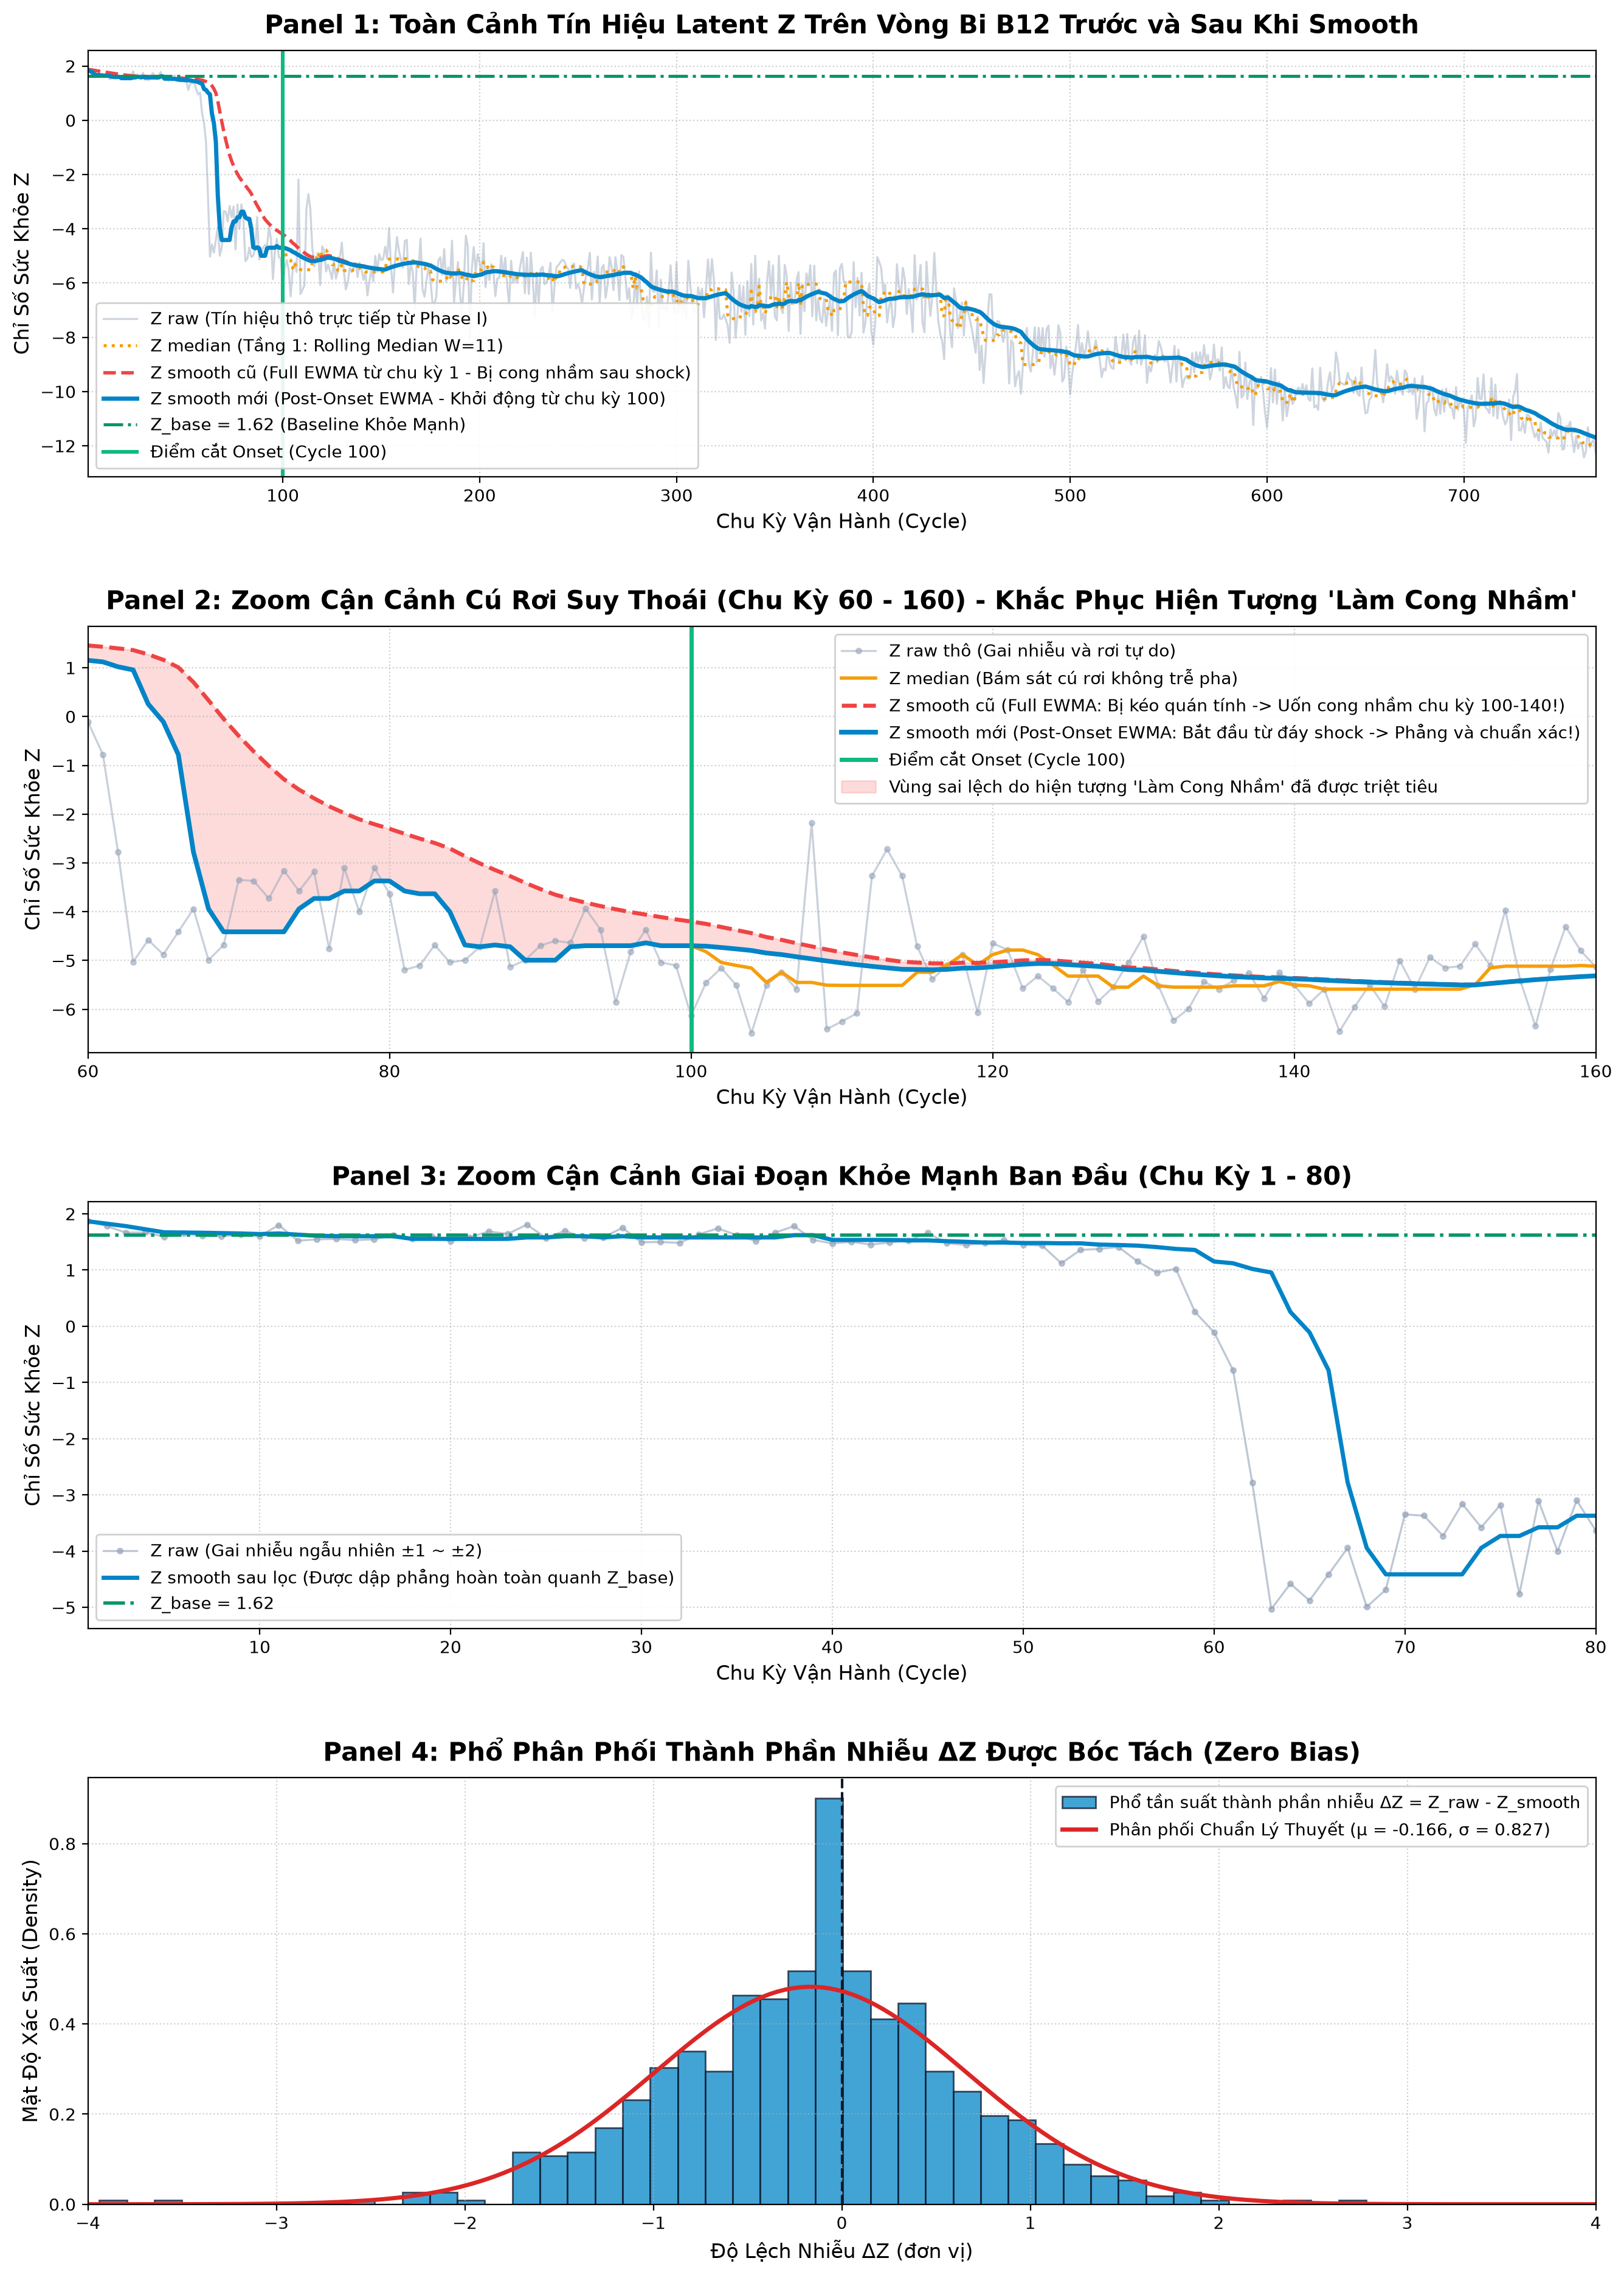

In [4]:
# Hiển thị đồ thị 4-panel chuyên sâu
plt.show()
